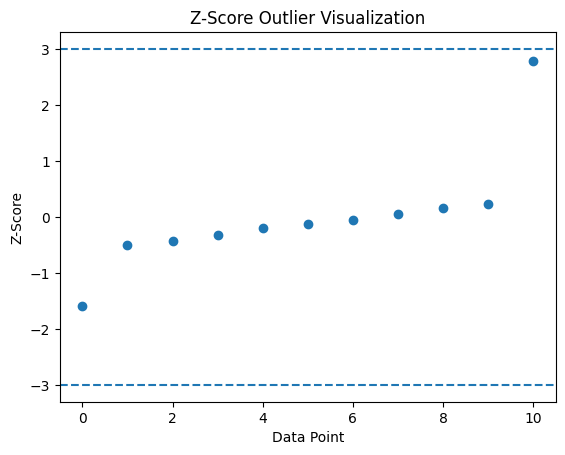

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore

data = np.array([-20,10, 12, 15, 18, 20, 22, 25, 28, 30, 100])

z_scores = zscore(data)

plt.scatter(range(len(data)), z_scores)

plt.axhline(3, linestyle="--")
plt.axhline(-3, linestyle="--")

plt.xlabel("Data Point")
plt.ylabel("Z-Score")
plt.title("Z-Score Outlier Visualization")

plt.show()

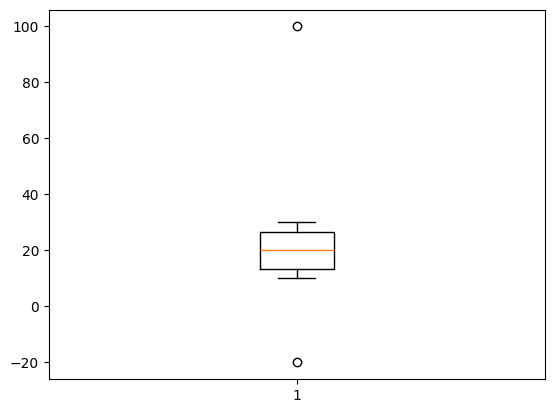

In [4]:
plt.boxplot(data)
plt.show()

In [5]:
import seaborn as sns 
import pandas as pd 
df=sns.load_dataset('tips')

In [6]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


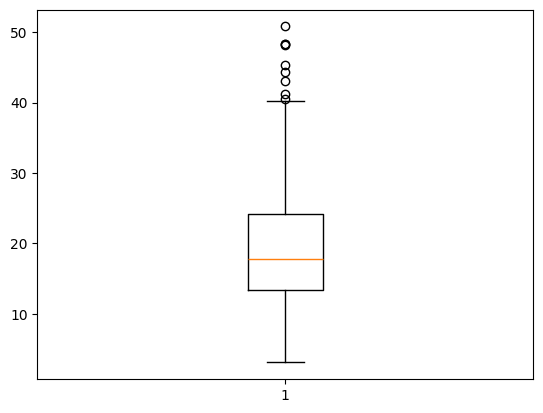

In [7]:
plt.boxplot(df['total_bill'])
plt.show()

In [8]:
Q1=df['total_bill'].quantile(0.25)
Q3=df['total_bill'].quantile(0.75)
iqr=Q3-Q1

lower=Q1-1.5*iqr
upper=Q3+1.5*iqr
df=df[(df['total_bill']<upper) & (df['total_bill']>lower)]

In [9]:
df.shape

(235, 7)

In [10]:
df.shape

(235, 7)

In [11]:
Q1=df['tip'].quantile(0.25)
Q3=df['tip'].quantile(0.75)
iqr=Q3-Q1
print('iqr--------',iqr)

lower=Q1-1.5*iqr
print('lower--------',lower)
upper=Q3+1.5*iqr
print('upper------',upper)

iqr-------- 1.5
lower-------- -0.25
upper------ 5.75


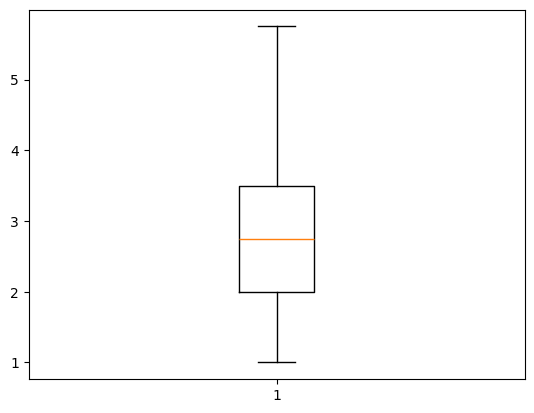

In [12]:
df['tip']=df['tip'].clip(upper=upper)
plt.boxplot(df['tip'])
plt.show()

In [13]:
from sklearn.preprocessing  import StandardScaler,OneHotEncoder,LabelEncoder,MinMaxScaler
from sklearn.compose import ColumnTransformer


In [14]:
df.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='object')

In [15]:
num_fea=['total_bill']
ohe_fea=['sex', 'smoker']
min_max=['tip']

In [16]:
ColumnTransformer(transformers=[('num',StandardScaler(),num_fea),
('min_max',MinMaxScaler(),min_max),
('cat',OneHotEncoder(drop='first'),ohe_fea),],
remainder='passthrough'
)

ColumnTransformer(remainder='passthrough',
                  transformers=[('num', StandardScaler(), ['total_bill']),
                                ('min_max', MinMaxScaler(), ['tip']),
                                ('cat', OneHotEncoder(drop='first'),
                                 ['sex', 'smoker'])])

In [17]:
transformer=ColumnTransformer(transformers=[('num',StandardScaler(),num_fea),
('min_max',MinMaxScaler(),min_max),
('cat',OneHotEncoder(drop='first'),ohe_fea),],
remainder='passthrough'
)

In [18]:
transformer.fit_transform(df)

array([[-0.2436713240621389, 0.002105263157894749, 0.0, ..., 'Sun',
        'Dinner', 2],
       [-1.1395807953545036, 0.1389473684210526, 1.0, ..., 'Sun',
        'Dinner', 3],
       [0.29791605557625356, 0.5263157894736842, 1.0, ..., 'Sun',
        'Dinner', 3],
       ...,
       [0.5215566153274304, 0.21052631578947367, 1.0, ..., 'Sat',
        'Dinner', 2],
       [-0.13185104418655025, 0.15789473684210525, 1.0, ..., 'Sat',
        'Dinner', 2],
       [-0.002516744571411735, 0.42105263157894735, 0.0, ..., 'Thur',
        'Dinner', 2]], dtype=object)

In [19]:
pd.DataFrame(transformer.fit_transform(df),columns=transformer.get_feature_names_out())

,num__total_bill,min_max__tip,cat__sex_Male,cat__smoker_Yes,remainder__day,remainder__time,remainder__size
0,-0.243671,0.002105,0.0,0.0,Sun,Dinner,2
1,-1.139581,0.138947,1.0,0.0,Sun,Dinner,3
2,0.297916,0.526316,1.0,0.0,Sun,Dinner,3
3,0.657627,0.486316,1.0,0.0,Sun,Dinner,2
4,0.780225,0.549474,0.0,0.0,Sun,Dinner,4
...,...,...,...,...,...,...,...
230,1.378396,1.0,1.0,0.0,Sat,Dinner,3
231,1.129158,0.210526,0.0,1.0,Sat,Dinner,2
232,0.521557,0.210526,1.0,1.0,Sat,Dinner,2
233,-0.131851,0.157895,1.0,0.0,Sat,Dinner,2


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression


In [22]:
model = Pipeline([
    ("preprocessor", transformer),
    ("classifier", LogisticRegression())
])

In [23]:
model

c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\compose\_column_transformer.py:1623: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num', StandardScaler(),
                                                  ['total_bill']),
                                                 ('min_max', MinMaxScaler(),
                                                  ['tip']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['sex', 'smoker'])])),
                ('classifier', LogisticRegression())])